In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
import csv

In [10]:
warnings.filterwarnings('ignore')

df = pd.read_csv('linkdin_Job_data.csv')

print("--- DATA BEFORE ---")
print(df.info())
print(f"\nDuplicated row: {df.duplicated().sum()}")
print("\nMissing Values Table:")
print(pd.DataFrame({
    'missing_value' : df.isnull().sum(),
    'missing_value_percentage' : df.isnull().sum() / len(df) * 100
}))

--- DATA BEFORE ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7927 entries, 0 to 7926
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   job_ID              7927 non-null   int64  
 1   job                 7894 non-null   object 
 2   location            7894 non-null   object 
 3   company_id          0 non-null      float64
 4   company_name        7892 non-null   object 
 5   work_type           7736 non-null   object 
 6   full_time_remote    7848 non-null   object 
 7   no_of_employ        7603 non-null   object 
 8   no_of_application   7887 non-null   object 
 9   posted_day_ago      7920 non-null   object 
 10  alumni              4858 non-null   object 
 11  Hiring_person       5720 non-null   object 
 12  linkedin_followers  4814 non-null   object 
 13  hiring_person_link  5720 non-null   object 
 14  job_details         7881 non-null   object 
 15  Column1             0 non-null     

In [11]:
num_cols_dirty = ['no_of_application', 'linkedin_followers', 'alumni', 'posted_day_ago']

def quick_extract(val):
    if pd.isna(val): return np.nan
    match = re.search(r'([0-9,.]+)', str(val).replace(',', ''))
    return float(match.group(1)) if match else np.nan

temp_dirty = df[num_cols_dirty].copy()
for col in num_cols_dirty:
    temp_dirty[col] = temp_dirty[col].apply(quick_extract)

desc_dirty = temp_dirty.describe().transpose()
desc_dirty['median'] = temp_dirty.median()

columns_order = ['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']
desc_dirty = desc_dirty.reindex(columns=columns_order)

print("--- DESCRIPTIVE STATISTICS (DIRTY DATA NUMERIC ESTIMATES) ---")
display(desc_dirty)

--- DESCRIPTIVE STATISTICS (DIRTY DATA NUMERIC ESTIMATES) ---


,count,mean,median,std,min,25%,50%,75%,max
no_of_application,3649.0,6.037627e+01,25.0,6.966134e+01,1.0,8.00,25.0,98.0,200.0
linkedin_followers,4780.0,1.110509e+06,36276.5,3.030221e+06,2.0,5547.75,36276.5,449565.0,13136792.0
alumni,4858.0,7.818683e+02,3.0,2.519374e+03,1.0,3.00,3.0,29.0,28799.0
posted_day_ago,7920.0,8.538510e+00,6.0,8.192703e+00,1.0,2.00,6.0,12.0,59.0


In [12]:
df_clean = df.drop_duplicates(subset=['job_ID'], keep='first').copy()
df_clean = df_clean.drop(columns=['Column1', 'company_id'], errors='ignore')

df_clean[['city', 'state', 'country']] = df_clean['location'].str.split(', ', n=2, expand=True)
df_clean[['emp_type', 'level']] = df_clean['full_time_remote'].str.split(' · ', n=1, expand=True)

parts = df_clean['no_of_employ'].str.split(' · ', n=1, expand=True)
df_clean['emp_range'] = parts[0].str.replace(r'(?i)\s*employees', '', regex=True).str.strip()
df_clean['industry'] = parts[1]

def to_hours(val):
    v = str(val).lower()
    n_match = re.search(r'(\d+)', v)
    n = int(n_match.group(1)) if n_match else 0
    if 'week' in v: return n * 24 * 7
    if 'month' in v: return n * 24 * 30
    if 'day' in v: return n * 24
    if 'hour' in v: return n
    return 0

df_clean['posted_hours_ago'] = df_clean['posted_day_ago'].apply(to_hours)

def scale_numeric(val):
    if pd.isna(val) or str(val).lower() in ['nan', 'none', 'null']:
        return 0
    val = str(val).upper().replace(',', '')
    match = re.search(r'([0-9.]+)([KM]?)', val)
    if match:
        num = float(match.group(1))
        suffix = match.group(2)
        if suffix == 'K': num *= 1000
        elif suffix == 'M': num *= 1000000
        return int(num)
    return 0

for c in ['no_of_application', 'linkedin_followers', 'alumni']:
    df_clean[c] = df_clean[c].apply(scale_numeric)

df_clean['Hiring_person'] = df_clean['Hiring_person'].str.split('(').str[0].str.strip()

cols = [
    'job_ID', 'job', 'company_name', 'work_type',
    'city', 'state', 'country', 'emp_type', 'level', 'emp_range',
    'industry', 'no_of_application', 'posted_hours_ago', 'alumni',
    'Hiring_person', 'linkedin_followers', 'hiring_person_link', 'job_details'
]

res = df_clean[cols].fillna('null')

print("--- DATA CLEANED ---")
print(res.info())

--- DATA CLEANED ---
<class 'pandas.core.frame.DataFrame'>
Index: 5843 entries, 0 to 7926
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   job_ID              5843 non-null   int64 
 1   job                 5843 non-null   object
 2   company_name        5843 non-null   object
 3   work_type           5843 non-null   object
 4   city                5843 non-null   object
 5   state               5843 non-null   object
 6   country             5843 non-null   object
 7   emp_type            5843 non-null   object
 8   level               5843 non-null   object
 9   emp_range           5843 non-null   object
 10  industry            5843 non-null   object
 11  no_of_application   5843 non-null   int64 
 12  posted_hours_ago    5843 non-null   int64 
 13  alumni              5843 non-null   int64 
 14  Hiring_person       5843 non-null   object
 15  linkedin_followers  5843 non-null   int64 
 16  hiring_p

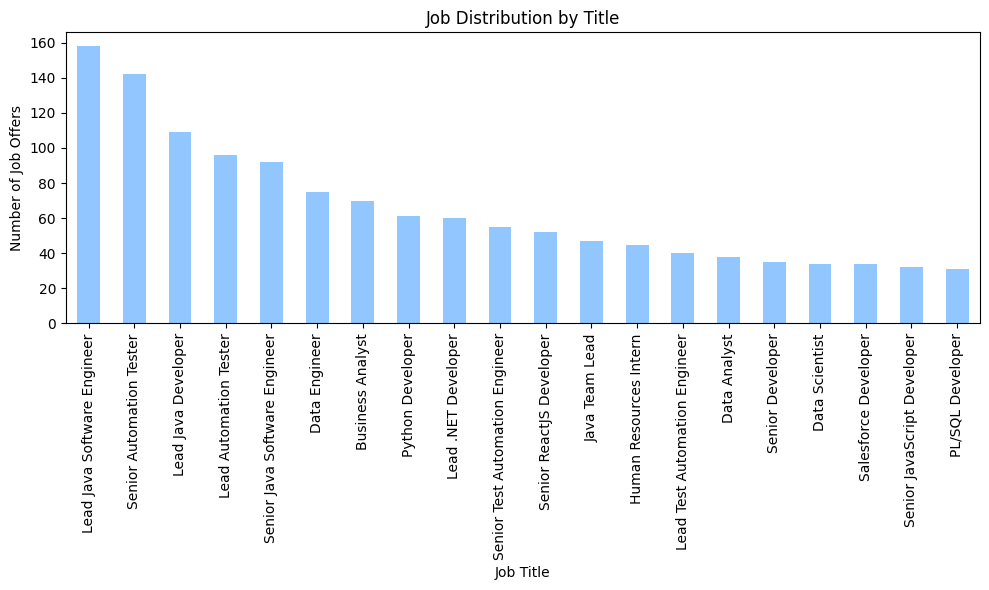

In [13]:
res.to_csv('cleaned_linkedin_jobs.csv', index=False, quoting=csv.QUOTE_ALL)
plt.style.use('seaborn-v0_8-pastel')


job_counts = res['job'].value_counts().head(20)
job_counts.plot(kind='bar', figsize=(10, 6))
plt.xlabel("Job Title")
plt.ylabel("Number of Job Offers")
plt.title("Job Distribution by Title")
plt.tight_layout()
plt.show()

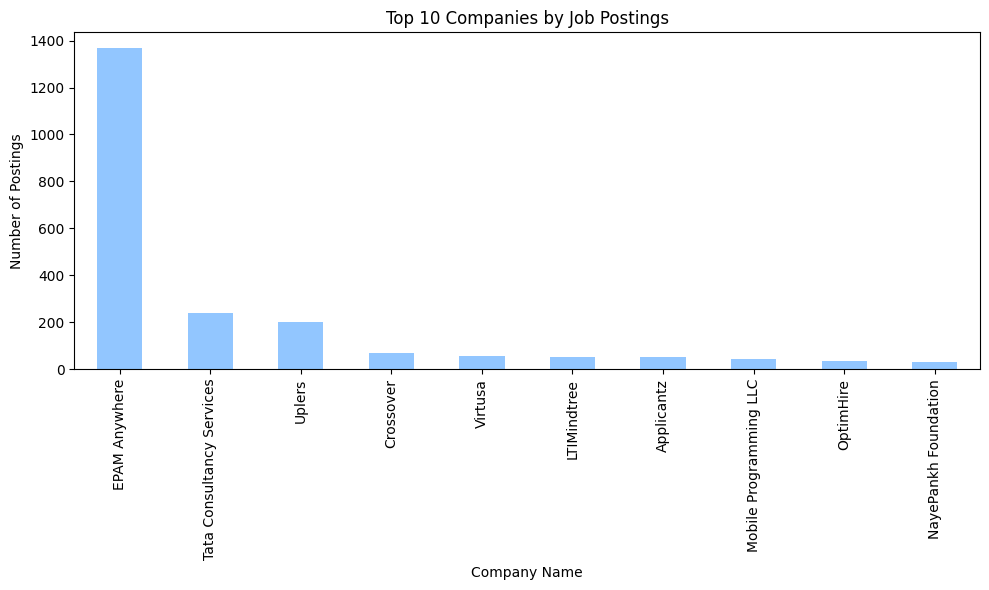

In [14]:
company_name_counts = res['company_name'].value_counts().head(10)
company_name_counts.plot(kind='bar', figsize=(10, 6))
plt.xlabel("Company Name")
plt.ylabel("Number of Postings")
plt.title("Top 10 Companies by Job Postings")
plt.tight_layout()
plt.show()

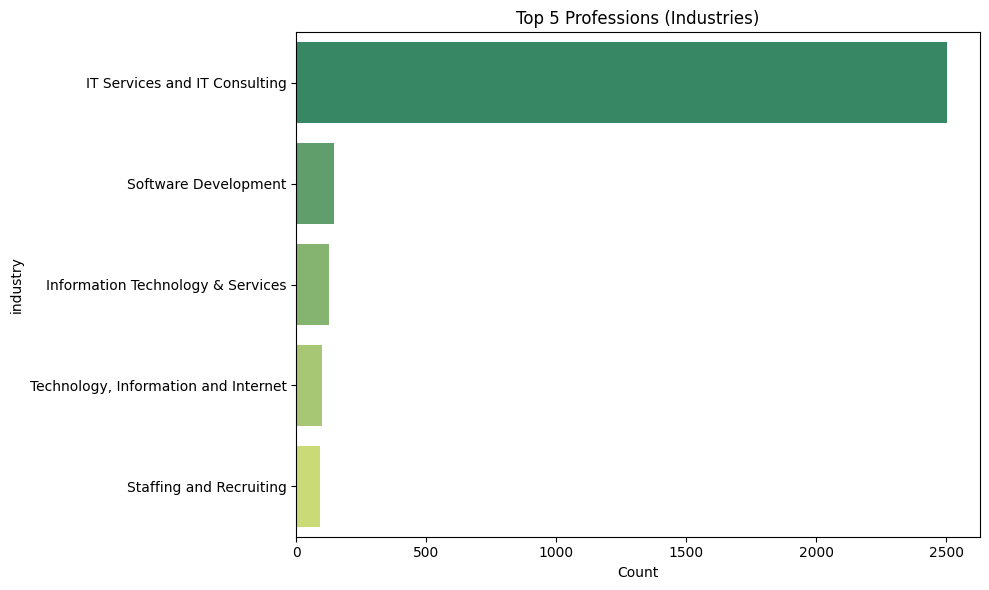

In [15]:
plt.figure(figsize=(10, 6))
top_professions = res[res['industry'] != 'null']['industry'].value_counts().head(5)
sns.barplot(x=top_professions.values, y=top_professions.index, palette='summer')
plt.title('Top 5 Professions (Industries)')
plt.xlabel('Count')
plt.tight_layout()
plt.savefig('top_professions.png')
plt.show()

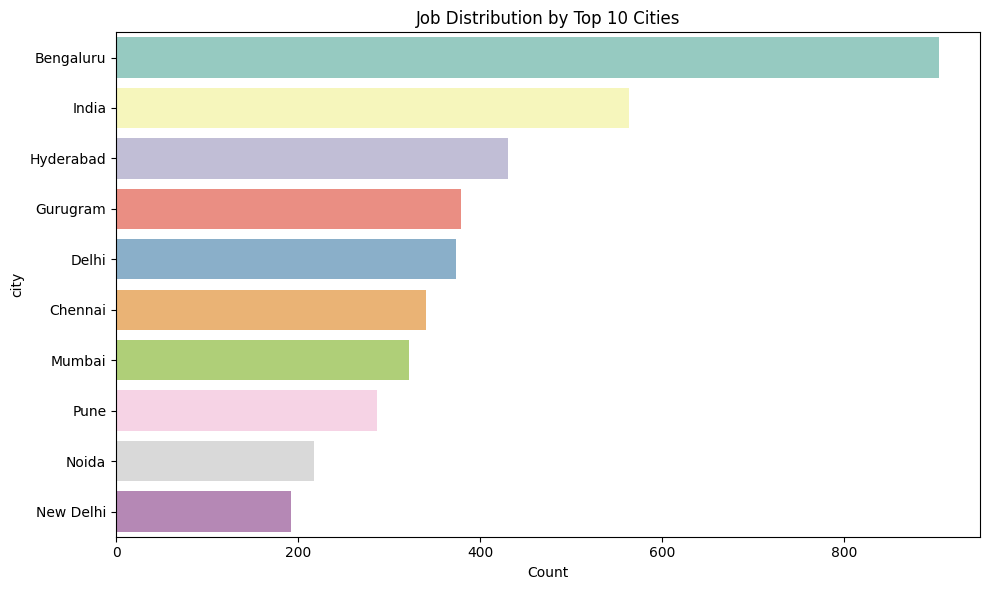

In [16]:
plt.figure(figsize=(10, 6))
location_counts = res[res['city'] != 'null']['city'].value_counts().head(10)
sns.barplot(x=location_counts.values, y=location_counts.index, palette='Set3')
plt.title('Job Distribution by Top 10 Cities')
plt.xlabel('Count')
plt.tight_layout()
plt.savefig('job_location_dist.png')
plt.show()

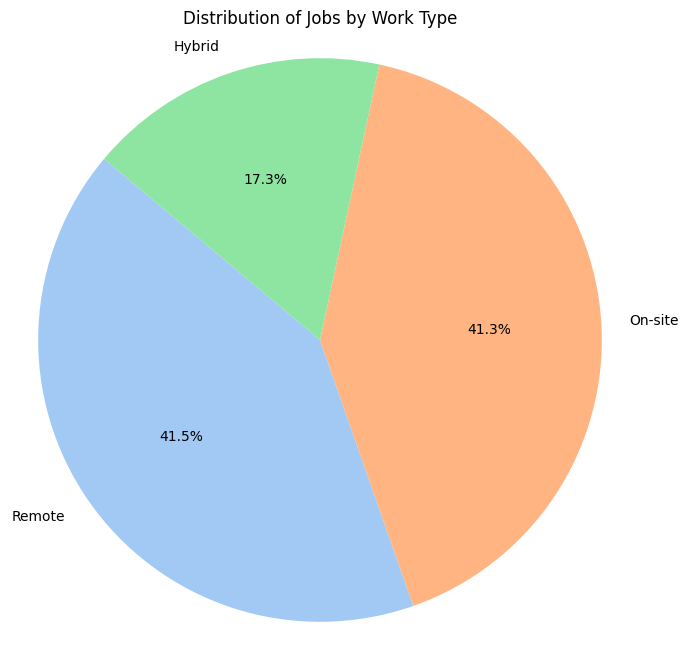

In [17]:
plt.figure(figsize=(8, 8))
work_type_counts = res[res['work_type'] != 'null']['work_type'].value_counts()
plt.pie(work_type_counts, labels=work_type_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Distribution of Jobs by Work Type')
plt.axis('equal')
plt.show()

CORRELATION ANALYSIS

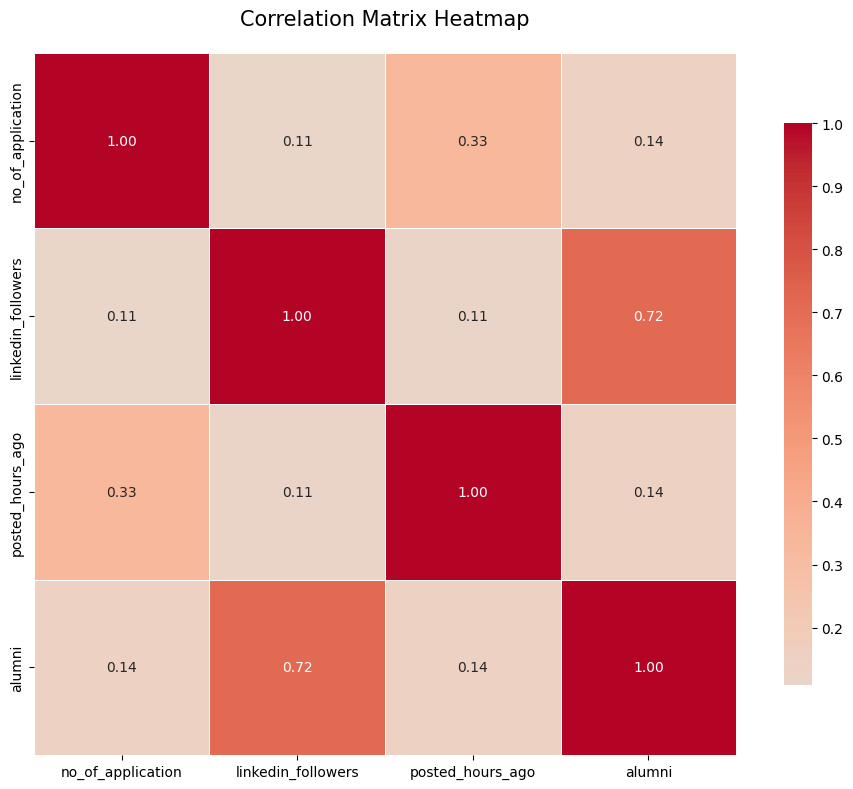

In [18]:
num_cols = ['no_of_application', 'linkedin_followers', 'posted_hours_ago', 'alumni']
corr_df = res[num_cols].replace('null', 0).astype(float)
corr_matrix = corr_df.corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Matrix Heatmap', fontsize=15, pad=20)
plt.tight_layout()
plt.show()

In [19]:
num_cols = ['no_of_application', 'linkedin_followers', 'posted_hours_ago', 'alumni']
desc_stats = res[num_cols].describe().transpose()
desc_stats['median'] = res[num_cols].median()
columns_order = ['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']
desc_stats = desc_stats.reindex(columns=columns_order)

print("--- DESCRIPTIVE STATISTICS ---")
display(desc_stats)

--- DESCRIPTIVE STATISTICS ---


,count,mean,median,std,min,25%,50%,75%,max
no_of_application,5843.0,23.526955,0.0,5.200916e+01,0.0,0.0,0.0,15.0,200.0
linkedin_followers,5843.0,585705.246791,2389.0,2.243471e+06,0.0,0.0,2389.0,98710.5,13136792.0
posted_hours_ago,5843.0,28.443950,12.0,3.847374e+01,0.0,6.0,12.0,24.0,168.0
alumni,5843.0,409.786753,2.0,1.866503e+03,0.0,0.0,2.0,3.0,28799.0


PREVIEW

In [20]:
res_valid_wt = res[res['work_type'] != 'null']
wt_stats = res_valid_wt['work_type'].value_counts(normalize=True)
dominant_val = wt_stats.values[0] * 100
dominant_label = wt_stats.index[0]

final_summary = {
    'Indikator': [
        'Total posting pekerjaan',
        'Jumlah judul pekerjaan unik',
        'Jumlah perusahaan unik',
        'Jumlah kota unik',
        'Rata-rata pelamar per posting',
        'Median pelamar per posting',
        'Dominasi work_type'
    ],
    'Nilai': [
        len(res),
        res['job'].nunique(),
        res['company_name'].nunique(),
        res[res['city'] != 'null']['city'].nunique(),
        f"{res['no_of_application'].mean():.1f}",
        int(res['no_of_application'].median()),
        f"{dominant_label} ({dominant_val:.1f}%)"
    ],
    'Keterangan': [
        'Data setelah pembersihan',
        'Variasi posisi kerja',
        'Entitas bisnis yang terdaftar',
        'Distribusi geografis (berdasarkan kota)',
        'Rerata minat pelamar',
        'Nilai tengah distribusi pelamar',
        'Tren cara kerja (berdasarkan data valid)'
    ]
}

display(pd.DataFrame(final_summary))

,Indikator,Nilai,Keterangan
0,Total posting pekerjaan,5843,Data setelah pembersihan
1,Jumlah judul pekerjaan unik,2988,Variasi posisi kerja
2,Jumlah perusahaan unik,2495,Entitas bisnis yang terdaftar
3,Jumlah kota unik,149,Distribusi geografis (berdasarkan kota)
4,Rata-rata pelamar per posting,23.5,Rerata minat pelamar
5,Median pelamar per posting,0,Nilai tengah distribusi pelamar
6,Dominasi work_type,Remote (41.5%),Tren cara kerja (berdasarkan data valid)
